# 1. Data and starting model

    The SED of MG3 J163554+3629 and the template model from its shape (`SEDShape` + `ObsConstrain`).
    The template is only the starting point for the fits in notebook 2.

In [1]:
%run mg3_setup.py

JetSeT version: 1.3.0
---> excluding  data_set/s ['-1']
filter -1 46
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=46
points: 46  (detections 40, UL 6), in fit range 38, in 3-79 keV 11


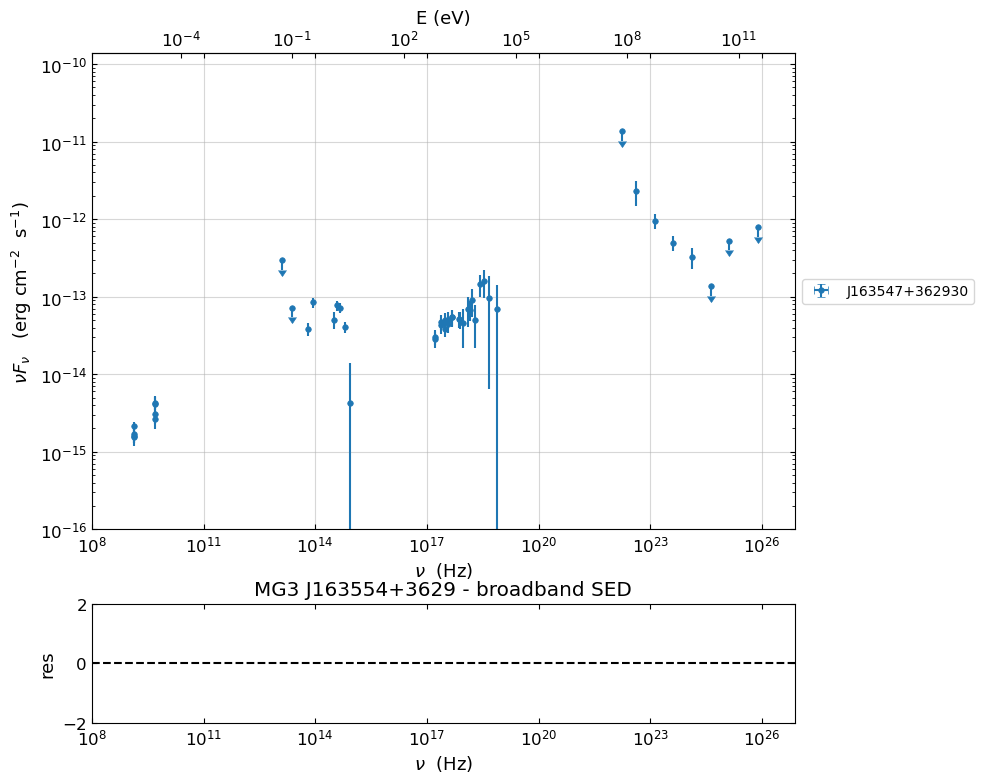

In [2]:
p_data = sed_data.plot_sed()
p_data.setlim(y_min=1e-16, x_min=1e8)
plt.title('MG3 J163554+3629 - broadband SED')
plt.savefig(os.path.join(FIG_DIR, 'SED_data.png'))
plt.show()


*** evaluating spectral indices for data ***


*** Log-Polynomial fitting of the synchrotron component ***
---> first blind fit run,  fit range: [9, 16]
---> class:  ISP

--> class:  LSP




model name,name,val,bestfit val,err +,err -,start val,fit range min,fit range max,frozen
LogParabolaEp,b,-8.256408e-02,-8.256408e-02,2.584721e-02,--,-6.224913e-02,-1.000000e+01,0.000000e+00,False
LogParabolaEp,Ep,1.330904e+01,1.330904e+01,5.717990e-01,--,1.413585e+01,0.000000e+00,3.000000e+01,False
LogParabolaEp,Sp,-1.333490e+01,-1.333490e+01,7.469589e-02,--,-1.320459e+01,-3.000000e+01,0.000000e+00,False
BBB,nuFnu_p_BBB,-1.338371e+01,-1.338371e+01,1.806069e-01,--,-1.320459e+01,-1.520459e+01,-1.120459e+01,False
BBB,nu_scale,4.312914e-02,4.312914e-02,6.422704e-03,--,0.000000e+00,-5.000000e-01,5.000000e-01,False


---> sync       nu_p=+1.330904e+01 (err=+5.717990e-01)  nuFnu_p=-1.333490e+01 (err=+7.469589e-02) curv.=-8.256408e-02 (err=+2.584721e-02)


*** Log-Polynomial fitting of the IC component ***
---> fit range: [16, 26]
---> LogCubic fit
====> simplex
====> migrad
====> simplex
====> migrad
====> simplex
====> migrad




model name,name,val,bestfit val,err +,err -,start val,fit range min,fit range max,frozen
LogCubic,b,-1.538966e-01,-1.538966e-01,2.246817e-02,--,-1.000000e+00,-1.000000e+01,0.000000e+00,False
LogCubic,c,-1.678536e-02,-1.678536e-02,4.144967e-03,--,-1.000000e+00,-1.000000e+01,1.000000e+01,False
LogCubic,Ep,2.203118e+01,2.203118e+01,1.132601e-01,--,2.269918e+01,0.000000e+00,3.000000e+01,False
LogCubic,Sp,-1.176847e+01,-1.176847e+01,1.030546e-01,--,-1.000000e+01,-3.000000e+01,0.000000e+00,False


---> IC         nu_p=+2.203118e+01 (err=+1.132601e-01)  nuFnu_p=-1.176847e+01 (err=+1.030546e-01) curv.=-1.538966e-01 (err=+2.246817e-02)



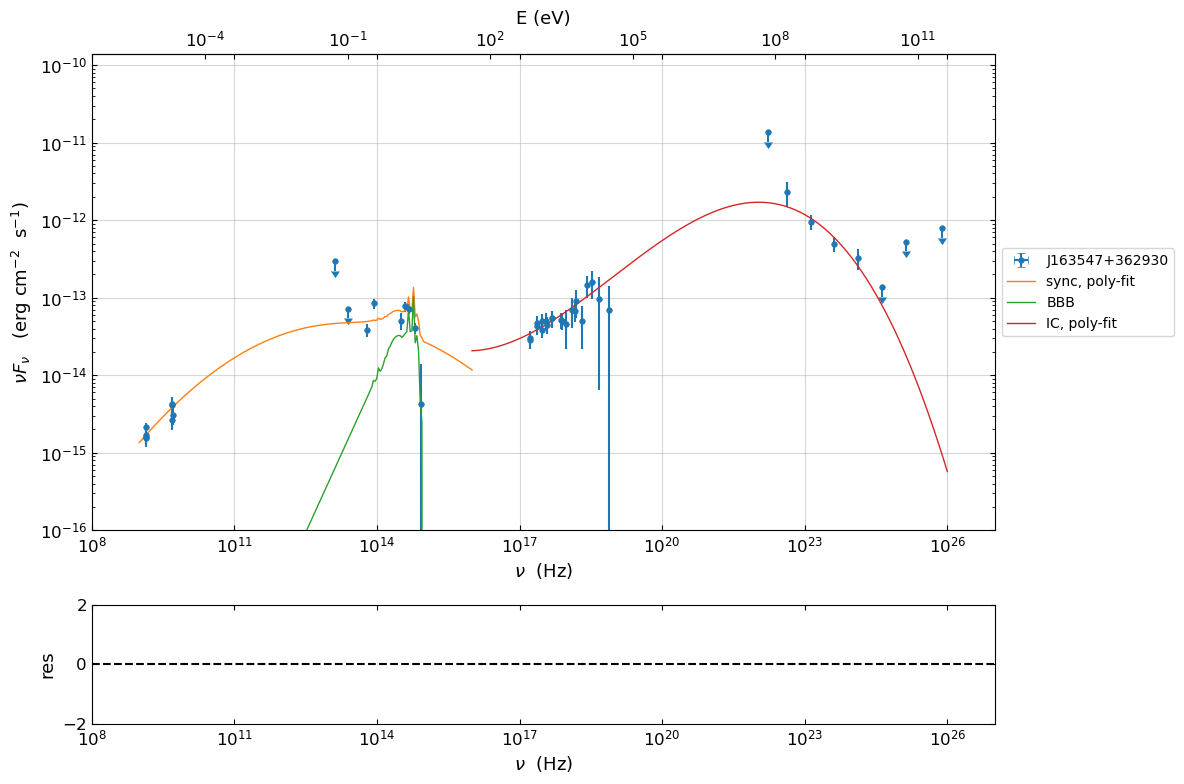


***  constrains parameters from observable ***

===> setting C threads to 8
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,R,region_size,cm,4.662820e+16,1.000000e+03,1.000000e+30,False,False
jet_leptonic,R_H,region_position,cm,1.500000e+18,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,5.861888e-02,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,theta,jet-viewing-angle,deg,3.000000e+00,0.000000e+00,9.000000e+01,False,False
jet_leptonic,BulkFactor,jet-bulk-factor,lorentz-factor*,1.850000e+01,1.000000e+00,1.000000e+05,False,False
jet_leptonic,z_cosm,redshift,,3.647763e+00,0.000000e+00,--,False,False
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,3.349778e+01,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,3.062804e+04,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,1.135226e+03,0.000000e+00,--,False,False




adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: z_cosm to  z_cosm
Template saved          : Template_ObsConstrain.pkl
External field frame    : blob
R  = 4.663e+16 cm   (R_H = 8.897e+17 cm)
R_BLR_in = 3.526e+17 cm,  R_DT = 2.351e+19 cm
accr_eff = 0.08333 | NH_cold_to_rel_e = 0.1


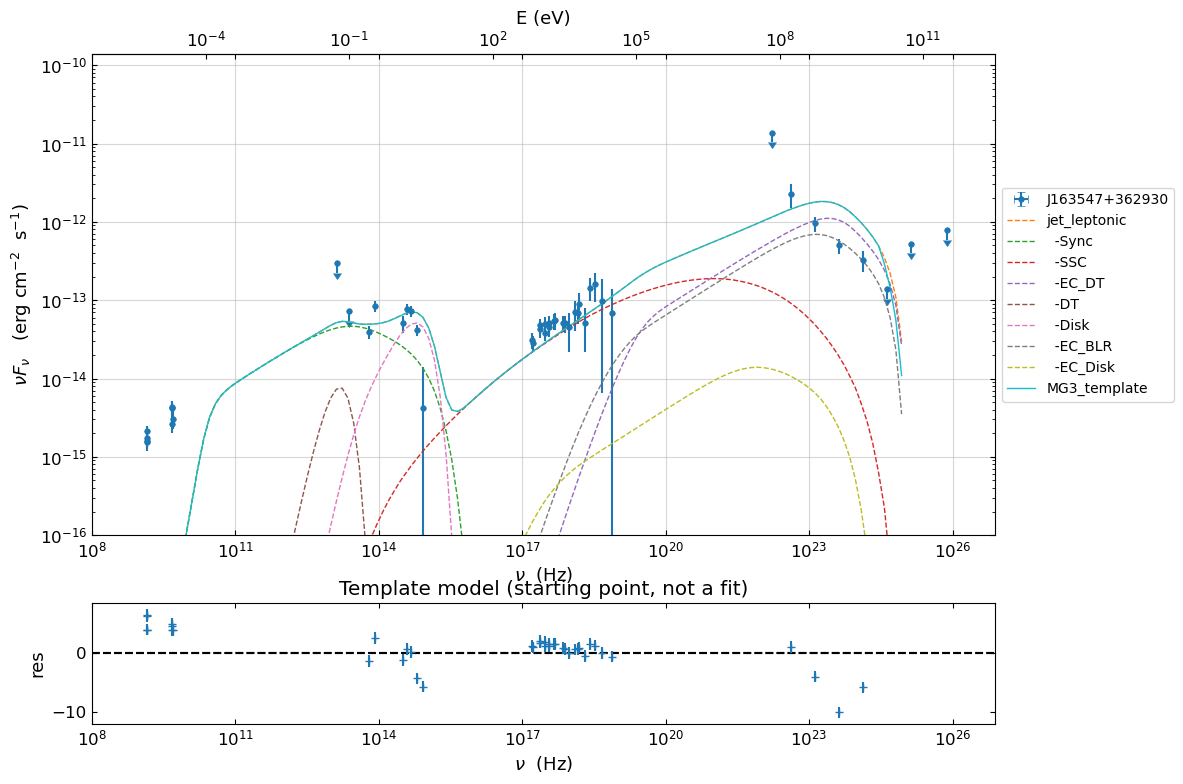

In [3]:
my_shape = SEDShape(sed_data)
my_shape.eval_indices(silent=True)

# Synchrotron peak: log-parabola + Big Blue Bump (accretion disc) template
my_shape.sync_fit(check_BBB_template=True,
                  check_host_gal_template=False,
                  use_log_par=True,
                  minimizer='lsb',
                  fit_range=[9, 16],
                  silent=True)

# Inverse-Compton peak
my_shape.IC_fit(fit_range=[16, 26], minimizer='minuit', silent=True)

p_shape = my_shape.plot_shape_fit()
p_shape.setlim(y_min=1e-16)
plt.savefig(os.path.join(FIG_DIR, 'SEDShape_fit.png'))
plt.show()

# 2. constrain a starting jet model from the observables
# theta = 3 deg, Gamma = 18.5, variability ~7 days, broken power-law electrons
sed_obspar = ObsConstrain(theta=3,
                          bulk_factor=18.5,
                          B_range=[0.02, 0.08],
                          distr_e='bkn',
                          t_var_sec=7 * 86400,
                          nu_cut_IR=1e9,
                          SEDShape=my_shape)

prefit_jet = sed_obspar.constrain_SSC_EC_model(electron_distribution_log_values=False,
                                               EC_components_list=['EC_DT', 'EC_BLR', 'EC_Disk'],
                                               R_H=1.5e18,
                                               disk_type='MultiBB',
                                               silent=True)
# ObsConstrain also ties the BLR and torus radii to the disc luminosity:
#   R_BLR_in = 3e17 (L_Disk/1e46)^0.5 cm,  R_BLR_out = 1.1 R_BLR_in,  R_DT = 2e19 (L_Disk/1e46)^0.5 cm

# 3. central-engine starting values
accr_par = prefit_jet.parameters.get_par_by_name('accr_eff')
accr_par.val_min = 0.040              # ObsConstrain default limits are [0.06, 0.10]; widen them
accr_par.val_max = 0.350

prefit_jet.set_par('L_Disk',   val=1.3817e46)
prefit_jet.set_par('M_BH',     val=9.8677e8)
prefit_jet.set_par('accr_eff', val=ETA_BASE)
prefit_jet.set_par('T_DT',     val=881.9)
prefit_jet.set_par('tau_DT',   val=0.1)          # torus covering factor
prefit_jet.set_par('tau_BLR',  val=0.1)          # BLR covering factor
prefit_jet.set_par('NH_cold_to_rel_e', val=NH_COLD_TO_REL_E)

# 4. blob size follows the jet opening angle: R = R_H * tan(theta_open)
R_start = prefit_jet.parameters.R.val
prefit_jet.add_user_par(name='theta_open', val=3, units='deg')
prefit_jet.make_dependent_par(par='R', depends_on=['R_H', 'theta_open'],
                              par_expr='np.tan(np.radians(theta_open))*R_H')
prefit_jet.set_par('R_H', val=R_start / np.tan(np.radians(3)))

# 5. external-field frame (same for every fit in this notebook)
prefit_jet.set_external_field_transf(EXT_FIELD_FRAME)

# 6. add EBL absorption (Franceschini et al. 2008), linked to the source redshift
template = FitModel(jet=prefit_jet, name='MG3_template')
ebl = EBLAbsorptionTemplate.from_name('Franceschini_2008')
template.add_component(ebl)
template.link_par(par_name='z_cosm', from_model='Franceschini_2008', to_model='jet_leptonic')
template.composite_expr = 'jet_leptonic * Franceschini_2008'

template.eval()
template.save_model(TEMPLATE_FILE)

# Checks
jet = template.jet_leptonic
print("Template saved          :", TEMPLATE_FILE)
print("External field frame    :", jet.get_external_field_transf())
print(f"R  = {jet.parameters.R.val:.3e} cm   (R_H = {jet.parameters.R_H.val:.3e} cm)")
print(f"R_BLR_in = {jet.parameters.R_BLR_in.val:.3e} cm,  R_DT = {jet.parameters.R_DT.val:.3e} cm")
print("accr_eff =", round(jet.parameters.accr_eff.val, 5),
      "| NH_cold_to_rel_e =", jet.parameters.NH_cold_to_rel_e.val)

p_tmp = template.plot_model(sed_data=sed_data)
p_tmp.setlim(y_min=1e-16, x_min=1e8)
plt.title('Template model (starting point, not a fit)')
plt.savefig(os.path.join(FIG_DIR, 'SED_template.png'))
plt.show()